# Step 1 : Preprocessing du dataset supervisé (ERA5-Land, Algérie 2015-2026)

**Objectif** : produire un dataset prêt à l'emploi pour prédire la **classe de t2m du mois suivant** (3 classes de largeur égale), avec split chronologique et mise à l'échelle.

## Ordre des étapes et justification (à reprendre dans le rapport)

| # | Étape | Pourquoi à cette place |
|---|-------|------------------------|
| 0 | Chargement, tri, contrôle du panel (cellule × mois) | Le décalage temporel de la cible n'est valide que si chaque cellule a une série mensuelle complète et ordonnée. |
| 1 | **Suppression des variables fortement corrélées** (|r| ≥ seuil) | Avant le split, comme demandé. La détection porte uniquement sur les **features** (Pearson et Spearman), jamais sur la cible : aucune information des étiquettes du test n'est utilisée. Faite avant les transformations : une variable redondante ne mérite ni transformation ni scaling. |
| 2 | Construction de la cible t2m(t+1), suppression du dernier mois | Le `shift(-1)` doit être fait par cellule **avant** le split, sur la série contiguë. Le dernier mois (sept. 2026) n'a pas de cible : ses lignes sont retirées. |
| 3 | **Split chronologique** train / test | Tout paramètre appris ensuite (médiane `s`, bornes des classes, statistiques du scaler) l'est sur le train seul : le split précède toutes les étapes qui apprennent quelque chose. |
| 4 | Traitement des outliers (transformations par variable) | Transformation plutôt que suppression de lignes : les valeurs extrêmes sont physiques (désert vs nord humide) et supprimer des lignes casserait la continuité du panel. Paramètre `s` calculé sur le train. Faite **avant** le scaling pour que les statistiques robustes portent sur les variables déjà transformées. |
| 5 | Discrétisation de la cible (3 intervalles de largeur égale) | Bornes min/max calculées sur le **train** uniquement. Les valeurs du test hors de cette plage tombent dans la première ou la dernière classe. |
| 6 | Feature extraction (encodage cyclique du mois) | Le mois (1 à 12) est cyclique : décembre et janvier sont voisins. `sin`/`cos` le rendent explicite pour KNN et SVM. |
| 7 | **Feature scaling** (RobustScaler, fit sur le train) | En dernier : il opère sur les variables transformées. Le scaler robuste (médiane/IQR) limite l'influence des extrêmes restants. |
| 8 | Analyse des classes, baselines, sauvegarde | Analyse sur le split final, puis export du dataset, du scaler et de la configuration. |

In [ ]:
import os, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from scipy import stats
from sklearn.preprocessing import RobustScaler
from sklearn.metrics import accuracy_score, f1_score

warnings.filterwarnings("ignore", category=FutureWarning)

try:  # Colab : montage de Drive ; ailleurs on ignore
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    pass

sns.set_style("whitegrid")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 170)

BASE = os.environ.get("DM_BASE", "/content/drive/MyDrive/data mining")
IN_FILE = f"{BASE}/era5_land_algeria_2x2_tidy_corrige.parquet"
OUT_DIR = f"{BASE}/supervised_dataset"
os.makedirs(OUT_DIR, exist_ok=True)


TEST_START = pd.Timestamp("2024-01-01")
CORR_THRESHOLD = 0.999

CLASS_NAMES = ["Froid", "Tempéré", "Chaud"]

RAW_VARS = ["d2m", "slhf", "ssr", "str", "sshf", "ro", "e", "u10", "v10", "sp", "tp"]
NEG_LOG_VARS = ["slhf", "e"]
POS_LOG1P_VARS = ["tp", "ro"]
NEG_EPS = 1e-12

KEEP_PRIORITY = ["ssr", "slhf", "tp", "str", "sshf", "ro", "e", "d2m", "u10", "v10", "sp"]
assert sorted(KEEP_PRIORITY) == sorted(RAW_VARS)

Mounted at /content/drive


## 0. Chargement et contrôle du panel

In [ ]:
df = pd.read_parquet(IN_FILE)
df = df.sort_values(["cell_id", "time"]).reset_index(drop=True)

n_cells, n_months = df["cell_id"].nunique(), df["time"].nunique()
print("Dimensions        :", df.shape)
print("Cellules          :", n_cells)
print("Mois              :", n_months, f"({df['time'].min().date()} -> {df['time'].max().date()})")

# --- contrôles bloquants ---
assert len(df) == n_cells * n_months, "Panel incomplet (cellule x mois)"
assert not df.duplicated(["cell_id", "time"]).any(), "Doublons (cellule, mois)"
assert df[["t2m"] + RAW_VARS].notna().all().all(), "Valeurs manquantes"
pas = pd.Series(np.sort(df["time"].unique())).diff().dropna().dt.days
assert pas.between(28, 31).all(), "Série mensuelle non contiguë"
print("Contrôles du panel : OK")

keep = ["cell_id", "latitude", "longitude", "time", "year", "month", "t2m"] + RAW_VARS
df = df[keep]

Dimensions        : (764925, 18)
Cellules          : 5425
Mois              : 141 (2015-01-01 -> 2026-09-01)
Contrôles du panel : OK


**Note : chargement et contrôle du panel**

**Ce que nous avons fait.** Nous avons chargé le dataset nettoyé (ERA5-Land, Algérie, moyennes mensuelles, grille agrégée 2×2), trié par cellule puis par date, et vérifié qu'il forme un panel complet : autant de lignes que de cellules × mois, aucun doublon (cellule, mois), aucune valeur manquante, mois strictement consécutifs.

**Justification.** La cible est la température du mois suivant, obtenue par un décalage temporel au sein de chaque cellule. Ce décalage n'a de sens que si chaque série mensuelle est complète, ordonnée et sans trou. Les contrôles sont des `assert` : le notebook s'arrête si une hypothèse est fausse, au lieu de produire silencieusement un dataset erroné.

## 1. Suppression de la variable fortement corrélée (avant le split)



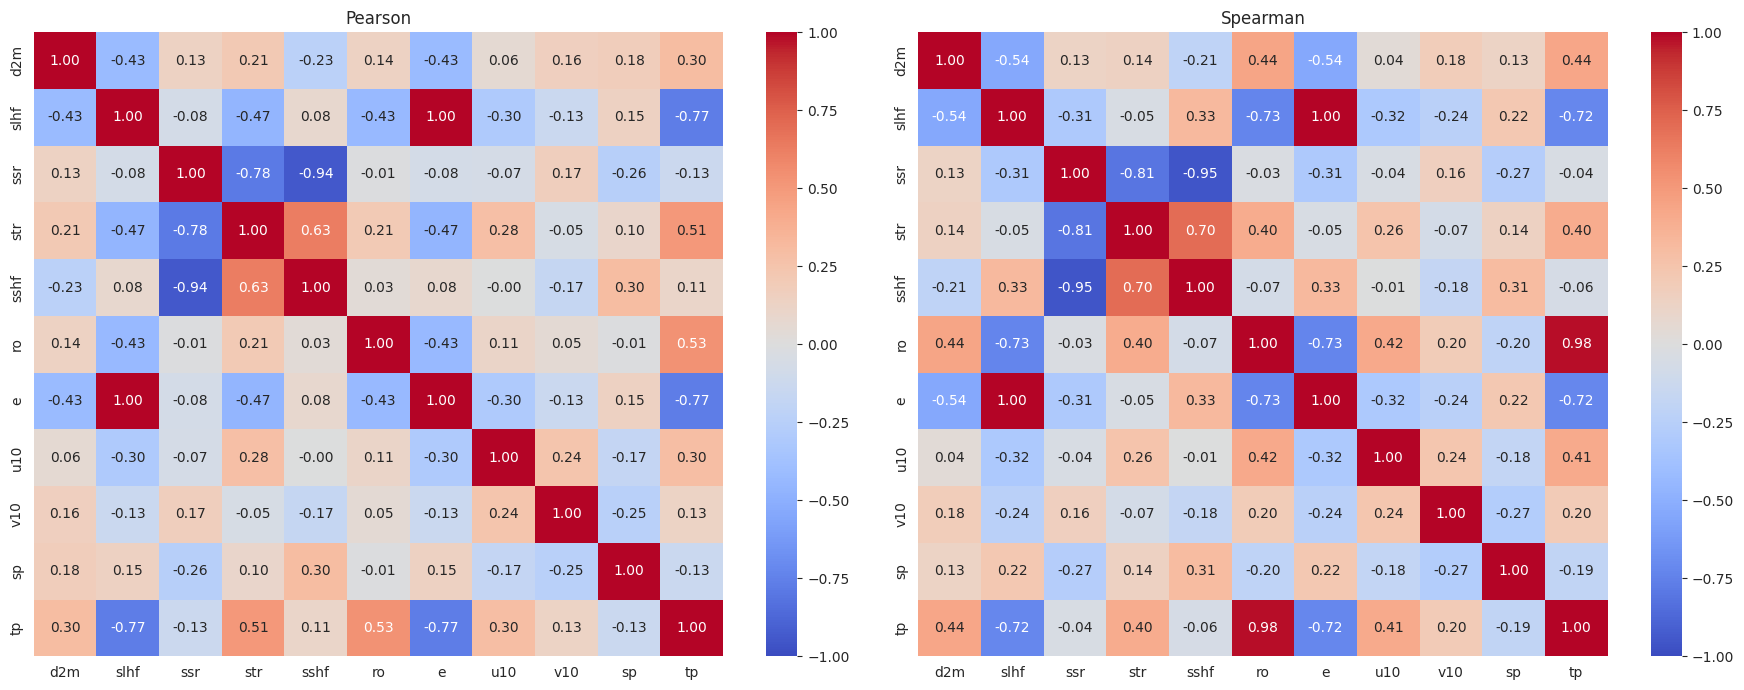

Seuil : |r| >= 0.999 (Pearson ou Spearman)  ->  1 paire(s) détectée(s)


,paire,Pearson,Spearman,gardée,supprimée
0,slhf / e,1.0,1.0,slhf,e


Variables supprimées : ['e']
Variables conservées : ['d2m', 'slhf', 'ssr', 'str', 'sshf', 'ro', 'u10', 'v10', 'sp', 'tp']
Corrélation max restante : 0.981
slhf / e : moyenne = 2.5008e+06 ; écart-type relatif = 3.43e-03  (Lv ~ 2.5e6 J/kg)
Colonnes restantes : ['cell_id', 'latitude', 'longitude', 'time', 'year', 'month', 't2m', 'd2m', 'slhf', 'ssr', 'str', 'sshf', 'ro', 'u10', 'v10', 'sp', 'tp']


In [ ]:
corr_p = df[RAW_VARS].corr(method="pearson")
corr_s = df[RAW_VARS].corr(method="spearman")
corr_max = np.maximum(corr_p.abs(), corr_s.abs())

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
for ax, c, titre in [(axes[0], corr_p, "Pearson"), (axes[1], corr_s, "Spearman")]:
    sns.heatmap(c, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, ax=ax)
    ax.set_title(titre)
plt.tight_layout(); plt.show()


paires = sorted([(a, b, corr_max.loc[a, b]) for i, a in enumerate(RAW_VARS) for b in RAW_VARS[i + 1:]
                 if corr_max.loc[a, b] >= CORR_THRESHOLD], key=lambda p: -p[2])

supprimees, lignes = [], []
for a, b, r in paires:
    if a in supprimees or b in supprimees:
        continue
    garde, drop = (a, b) if KEEP_PRIORITY.index(a) < KEEP_PRIORITY.index(b) else (b, a)
    supprimees.append(drop)
    lignes.append({"paire": f"{a} / {b}", "Pearson": corr_p.loc[a, b], "Spearman": corr_s.loc[a, b],
                   "gardée": garde, "supprimée": drop})

DROP_CORR = sorted(supprimees, key=RAW_VARS.index)
FEATURES_CLIM = [v for v in RAW_VARS if v not in DROP_CORR]
table_corr = pd.DataFrame(lignes)

print(f"Seuil : |r| >= {CORR_THRESHOLD} (Pearson ou Spearman)  ->  {len(paires)} paire(s) détectée(s)")
display(table_corr.round(3) if len(table_corr) else "Aucune paire au-dessus du seuil")
print("Variables supprimées :", DROP_CORR)
print("Variables conservées :", FEATURES_CLIM)


reste = corr_max.loc[FEATURES_CLIM, FEATURES_CLIM].to_numpy().copy()
np.fill_diagonal(reste, 0)
print(f"Corrélation max restante : {reste.max():.3f}")
assert reste.max() < CORR_THRESHOLD


ratio = df["slhf"] / df["e"]
print(f"slhf / e : moyenne = {ratio.mean():.4e} ; écart-type relatif = {ratio.std() / ratio.mean():.2e}  (Lv ~ 2.5e6 J/kg)")


df = df.drop(columns=DROP_CORR)
print("Colonnes restantes :", list(df.columns))

In [ ]:

proches = sorted([(a, b, corr_p.loc[a, b], corr_s.loc[a, b]) for i, a in enumerate(RAW_VARS) for b in RAW_VARS[i + 1:]
                  if 0.80 <= corr_max.loc[a, b] < CORR_THRESHOLD], key=lambda p: -max(abs(p[2]), abs(p[3])))
pd.DataFrame(proches, columns=["var 1", "var 2", "Pearson", "Spearman"]).round(3) if proches else "Aucune paire entre 0.80 et le seuil"

,var 1,var 2,Pearson,Spearman
0,ro,tp,0.534,0.981
1,ssr,sshf,-0.941,-0.954
2,ssr,str,-0.785,-0.809


**Note : suppression de la variable fortement corrélée**

**Ce que nous avons fait.** Nous avons calculé les corrélations de Pearson et de Spearman entre les 11 variables climatiques et retenu les paires avec |r| ≥ 0,999. Une seule paire est concernée : slhf / e, liées exactement par `e = slhf / Lv` (`Lv` ≈ 2,5·10⁶ J/kg, chaleur latente de vaporisation). Nous avons supprimé `e` et gardé `slhf`.

**Justification.**
- Deux variables liées par une constante portent exactement la même information. Les garder double leur poids dans les modèles à distance (KNN, SVM) et augmente la dimension sans rien apporter.
- Elles ont aussi les mêmes valeurs aberrantes (16,78 % en IQR, asymétrie −3,987 pour les deux) : aucun critère statistique ne permet de les départager. Nous gardons slhf parce que c'est un flux d'énergie, de même famille que `sshf`, `ssr` et `str`.
- Pearson et Spearman sont tous deux utilisés, car les variables sont très asymétriques (Pearson y est dominé par les extrêmes).
- L'étape est faite **avant le split**, sur les features seulement. La cible n'intervient pas, donc aucune information sur les étiquettes du test n'est utilisée.
- Les paires seulement fortement corrélées, sans être redondantes (par exemple `ssr`/`sshf` à environ −0,94, ou `ro`/`tp` corrélées surtout en rang), sont conservées : elles restent distinctes physiquement et le sujet impose ces variables.

## 2. Intégration de la cible : t2m du mois suivant

`shift(-1)` **par cellule** (jamais sur l'ensemble du tableau, sinon la dernière ligne d'une cellule récupérerait la première de la suivante). Le dernier mois n'a pas de mois suivant : ses lignes sont retirées.

In [ ]:
g = df.groupby("cell_id", sort=False)
df["t2m_next"] = g["t2m"].shift(-1)
df["time_next"] = g["time"].shift(-1)

ecart = (df["time_next"].dt.year * 12 + df["time_next"].dt.month) - (df["time"].dt.year * 12 + df["time"].dt.month)
assert ecart.dropna().eq(1).all(), "Décalage temporel incorrect"

n_avant = len(df)
data = df.dropna(subset=["t2m_next"]).reset_index(drop=True)
print(f"Lignes retirées (dernier mois, sans cible) : {n_avant - len(data)}  (= {n_cells} cellules x 1 mois)")
print("Dernier mois conservé (features) :", data["time"].max().date(), "-> cible :", data["time_next"].max().date())
print("Lignes restantes :", len(data))

Lignes retirées (dernier mois, sans cible) : 5425  (= 5425 cellules x 1 mois)
Dernier mois conservé (features) : 2026-08-01 -> cible : 2026-09-01
Lignes restantes : 759500


**Note : intégration de la cible**

**Ce que nous avons fait.** Nous avons décalé `t2m` d'un mois (`shift(-1)`) séparément pour chaque cellule, vérifié que l'écart entre les deux dates est bien d'un mois, puis retiré les lignes du dernier mois (une par cellule), qui n'ont pas de mois suivant.

**Justification.**
- Le décalage est fait **par cellule** : sur l'ensemble du tableau, la dernière ligne d'une cellule récupérerait la première ligne de la cellule suivante.
- Il est fait **avant le split**, car il exige la série contiguë de chaque cellule.
- Le dernier mois est supprimé plutôt que rempli : imputer une cible reviendrait à inventer l'étiquette.

## 3. Split chronologique train / test



In [ ]:
train = data[data["time"] < TEST_START].copy()
test  = data[data["time"] >= TEST_START].copy()

assert train["time_next"].max() <= test["time"].min()
assert train["time"].max() < test["time"].min()

resume_split = pd.DataFrame({
    "lignes":  [len(train), len(test)],
    "% lignes": [100 * len(train) / len(data), 100 * len(test) / len(data)],
    "mois":    [train["time"].nunique(), test["time"].nunique()],
    "début":   [train["time"].min().date(), test["time"].min().date()],
    "fin":     [train["time"].max().date(), test["time"].max().date()],
}, index=["train", "test"])
resume_split.round(1)

,lignes,% lignes,mois,début,fin
train,585900,77.1,108,2015-01-01,2023-12-01
test,173600,22.9,32,2024-01-01,2026-08-01


**Note : split chronologique**

**Ce que nous avons fait.** Le train contient tous les mois avant `TEST_START`, le test tous les mois suivants. Aucun mélange aléatoire.

**Justification.**
- L'objectif est de prédire le futur à partir du passé. Un split aléatoire mettrait dans le train des mois voisins de mois du test (forte autocorrélation temporelle et spatiale) et surestimerait les performances.
- Le split précède toutes les étapes qui apprennent un paramètre (transformations, bornes des classes, scaler) : ils sont donc calculés sur le train seul, sans fuite.
- La dernière cible du train est la température du premier mois du test. C'est une valeur d'entrée du test, jamais une étiquette du test : il n'y a pas de fuite.
- Le test contient 2026, année incomplète : sa distribution de classes diffère de celle du train (voir la section 8).

## 4. Traitement des outliers (par variable)

| Variable | Traitement | Raison |
|---|---|---|
| `slhf` (et `e` si conservée) | `np.log(-x)` | strictement négatives, asymétrie d'environ −4 |
| `tp`, `ro` | `np.log1p(x / s)`, avec `s` = médiane des valeurs **positives du train** | positives, beaucoup de valeurs proches de 0 (`ro` : ~19 % de zéros) ; `s` règle l'échelle propre à chaque variable |
| `d2m`, `sshf`, `u10`, `v10`, `sp`, `str` | aucun (scaling robuste ensuite) | outliers IQR rares (< 2 %), symétriques, valeurs physiques réelles |
| `ssr` | aucun | pas d'outlier |

Toutes les lignes sont conservées. Les paramètres (`s`) sont appris sur le train. Si l'une de ces variables a été supprimée à l'étape 3 (corrélation), son traitement est simplement ignoré.

In [ ]:
# ---- paramètres appris sur le TRAIN uniquement ----
pos_scale = {}
for v in POS_LOG1P_VARS:
    if v not in FEATURES_CLIM:
        continue                       # variable supprimée à l'étape 3
    x = train[v]
    pos_scale[v] = float(x[x > 0].median())
print("Échelle s (médiane des valeurs positives du train) :", {k: f"{val:.3e}" for k, val in pos_scale.items()})

TRANSFORM_PARAMS = {"neg_eps": NEG_EPS, "pos_scale": pos_scale}

def apply_transform(X, params=TRANSFORM_PARAMS):
    # Applique les transformations anti-outliers (sans toucher aux autres colonnes).
    X = X.copy()
    for v in NEG_LOG_VARS:
        if v in X.columns:
            X[v] = np.log(np.clip(-X[v], params["neg_eps"], None))
    for v in POS_LOG1P_VARS:
        if v in X.columns and v in params["pos_scale"]:
            X[v] = np.log1p(np.clip(X[v], 0, None) / params["pos_scale"][v])
    return X

# Garde-fou : combien de valeurs violent les hypothèses de signe ?
for nom, d in [("train", train), ("test", test)]:
    viol_neg = sum(int((d[v] >= 0).sum()) for v in NEG_LOG_VARS if v in FEATURES_CLIM)
    viol_pos = sum(int((d[v] < 0).sum()) for v in POS_LOG1P_VARS if v in FEATURES_CLIM)
    print(f"{nom:5s}: valeurs >= 0 dans slhf/e = {viol_neg} ; valeurs < 0 dans tp/ro = {viol_pos}")

X_train_t = apply_transform(train[FEATURES_CLIM])
X_test_t  = apply_transform(test[FEATURES_CLIM])

Échelle s (médiane des valeurs positives du train) : {'tp': '1.947e-02', 'ro': '1.136e-04'}
train: valeurs >= 0 dans slhf/e = 0 ; valeurs < 0 dans tp/ro = 0
test : valeurs >= 0 dans slhf/e = 0 ; valeurs < 0 dans tp/ro = 0


In [ ]:
def iqr_pct(x):
    q1, q3 = x.quantile([0.25, 0.75])
    iqr = q3 - q1
    return 100 * ((x < q1 - 1.5 * iqr) | (x > q3 + 1.5 * iqr)).mean()

traitement = {v: "log(-x)" for v in NEG_LOG_VARS if v in FEATURES_CLIM}
traitement.update({v: "log1p(x/s)" for v in POS_LOG1P_VARS if v in FEATURES_CLIM})

rapport = pd.DataFrame({
    "traitement":     [traitement.get(v, "aucun") for v in FEATURES_CLIM],
    "asym_avant":     [train[v].skew() for v in FEATURES_CLIM],
    "asym_après":     [X_train_t[v].skew() for v in FEATURES_CLIM],
    "%IQR_avant":     [iqr_pct(train[v]) for v in FEATURES_CLIM],
    "%IQR_après":     [iqr_pct(X_train_t[v]) for v in FEATURES_CLIM],
}, index=FEATURES_CLIM)
rapport.round(2)

,traitement,asym_avant,asym_après,%IQR_avant,%IQR_après
d2m,aucun,0.250000,0.25,1.13,1.13
slhf,log(-x),-4.020000,0.92,16.71,7.55
ssr,aucun,-0.100000,-0.10,0.00,0.00
str,aucun,0.350000,0.35,0.07,0.07
sshf,aucun,-0.380000,-0.38,0.87,0.87
ro,log1p(x/s),36.360001,2.10,16.22,7.47
u10,aucun,0.100000,0.10,0.68,0.68
v10,aucun,-0.220000,-0.22,0.95,0.95
sp,aucun,-0.840000,-0.84,1.83,1.83
tp,log1p(x/s),5.840000,1.23,15.05,2.60


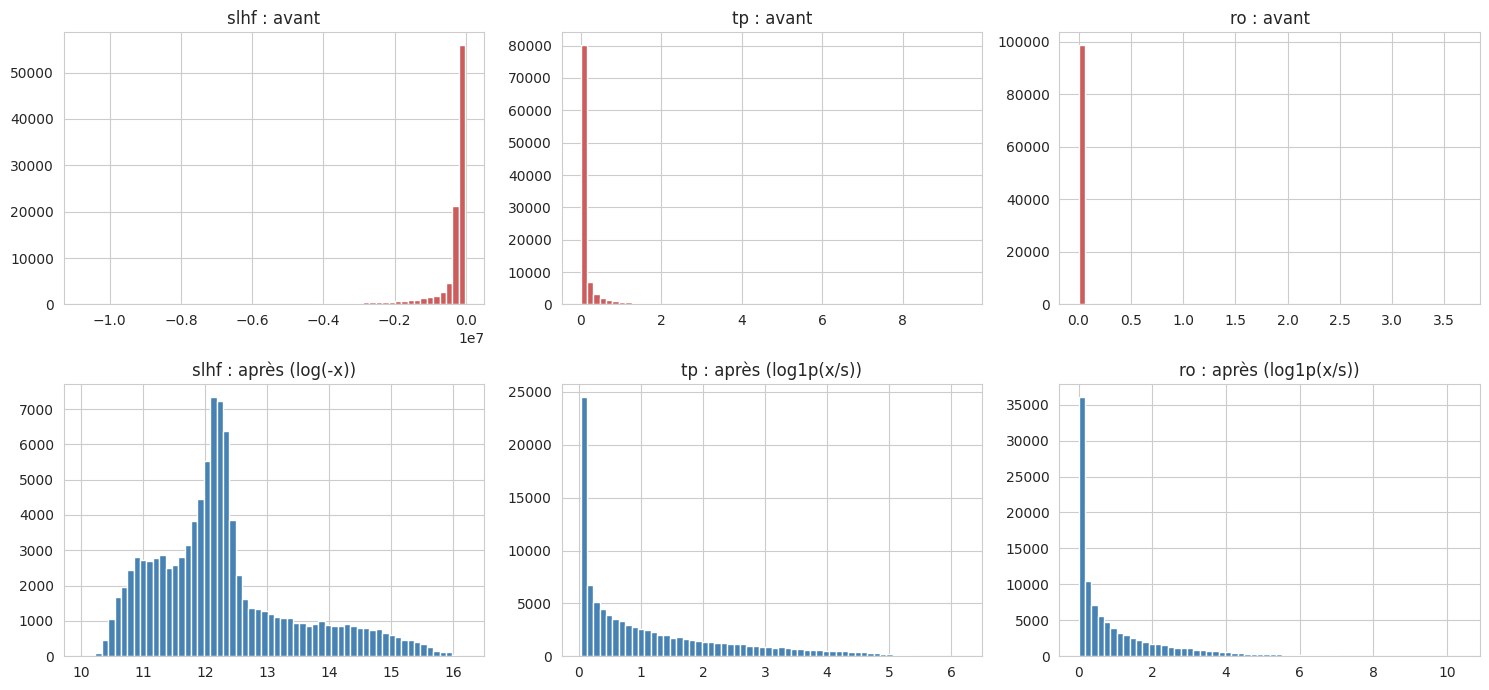

In [ ]:
vars_plot = [v for v in NEG_LOG_VARS + POS_LOG1P_VARS if v in FEATURES_CLIM]
ech = train.sample(n=min(100_000, len(train)), random_state=0).index
fig, axes = plt.subplots(2, len(vars_plot), figsize=(5 * len(vars_plot), 7), squeeze=False)
for j, v in enumerate(vars_plot):
    axes[0, j].hist(train.loc[ech, v], bins=60, color="indianred", edgecolor="white")
    axes[0, j].set_title(f"{v} : avant")
    axes[1, j].hist(X_train_t.loc[ech, v], bins=60, color="steelblue", edgecolor="white")
    axes[1, j].set_title(f"{v} : après ({traitement[v]})")
plt.tight_layout(); plt.show()

**Note : traitement des outliers**

**Ce que nous avons fait.** Nous avons traité les outliers par **transformation** variable par variable, sans supprimer de lignes :
- `slhf` : `log(-x)`.
- `tp`, `ro` : `log1p(x / s)`, avec `s` = médiane des valeurs positives du train.
- `d2m`, `sshf`, `u10`, `v10`, `sp`, `str` : aucune transformation (scaling robuste ensuite).
- `ssr` : rien à traiter.

**Justification.**
- **Pourquoi transformer et non supprimer** : les valeurs extrêmes sont physiques (désert contre nord humide), pas des erreurs de mesure. Supprimer des lignes casserait la continuité temporelle des séries et biaiserait les classes extrêmes.
- **`slhf`** est strictement négative, avec une asymétrie d'environ −4 : `log(-x)` compresse la queue.
- **`tp` et `ro`** sont positives, avec beaucoup de valeurs proches de 0 (`ro` contient environ 19 % de zéros). `log1p` est défini en 0. La division par `s` donne à chaque variable sa propre échelle : sans elle, `log1p(x) ≈ x` pour des valeurs très inférieures à 1 et n'étalerait presque rien (`ro` est bien plus petite que `tp`).
- **Variables non transformées** : leurs points aberrants IQR sont rares (moins de 2 %) et correspondent à des valeurs physiques réelles. Le `RobustScaler` limite leur influence.
- **`s` est calculé sur le train** pour qu'aucune information du test n'intervienne.
- Le tableau avant/après (asymétrie et % d'outliers IQR) et les histogrammes montrent l'effet des transformations.

## 5. Discrétisation de la cible

Trois intervalles de **largeur égale** sur la plage de la cible `t2m(t+1)`, avec min et max pris sur le **train**. Les valeurs du test hors de cette plage sont rattachées à la classe extrême la plus proche.

In [ ]:
t_min, t_max = float(train["t2m_next"].min()), float(train["t2m_next"].max())
edges = np.linspace(t_min, t_max, 4)
print("Bornes (train)  :", edges.round(2))
print("Largeur d'un intervalle :", round(edges[1] - edges[0], 2), "°C")

def to_class(t):
    # 0 = Froid : t <= e1 ; 1 = Tempéré : e1 < t <= e2 ; 2 = Chaud : t > e2
    return np.digitize(np.asarray(t), edges[1:-1], right=True)

train["y"] = to_class(train["t2m_next"])
test["y"]  = to_class(test["t2m_next"])

print("\nTest hors de la plage du train : "
      f"{int((test['t2m_next'] < t_min).sum())} sous le min, {int((test['t2m_next'] > t_max).sum())} au-dessus du max")

edges_all = np.linspace(data["t2m_next"].min(), data["t2m_next"].max(), 4)
print("Pour comparaison, bornes calculées sur toutes les données :", edges_all.round(2))

for d in (train, test):
    d["y_label"] = pd.Categorical.from_codes(d["y"], CLASS_NAMES)

Bornes (train)  : [ 0.28 13.86 27.44 41.03]
Largeur d'un intervalle : 13.58 °C

Test hors de la plage du train : 0 sous le min, 0 au-dessus du max
Pour comparaison, bornes calculées sur toutes les données : [ 0.28 13.86 27.44 41.03]


**Note : discrétisation de la cible**

**Ce que nous avons fait.** Nous avons divisé la plage de `t2m(t+1)` en **trois intervalles de largeur égale**, avec le min et le max du **train**. Les classes sont codées 0, 1, 2 (étiquettes de lecture : Froid, Tempéré, Chaud, c'est-à-dire classe basse, moyenne, haute). Les valeurs du test hors de la plage du train sont rattachées à la classe extrême la plus proche.

**Justification.**
- L'énoncé impose trois intervalles de largeur égale (et non des quantiles).
- Calculer les bornes sur le train évite d'utiliser le min et le max du test. Le notebook compte les valeurs du test hors plage pour mesurer l'effet.
- **Limites** : les bornes dépendent du minimum et du maximum, qui sont des valeurs extrêmes. Et des intervalles de largeur égale ne donnent pas des classes équilibrées : ce déséquilibre est analysé en section 8, et justifie l'usage du F1-macro en plus de l'accuracy.

## 6. Feature extraction : encodage cyclique du mois

`month` et `year` restent dans le dataset (comme demandé). On ajoute `month_sin` et `month_cos`, qui rapprochent décembre et janvier pour les modèles à distance (KNN, SVM). Ces deux colonnes sont déjà bornées dans [-1, 1] : elles ne sont pas re-scalées.

In [ ]:
def add_cyclic(X, month):
    X = X.copy()
    X["month"] = month.values
    X["month_sin"] = np.sin(2 * np.pi * month.values / 12)
    X["month_cos"] = np.cos(2 * np.pi * month.values / 12)
    return X

X_train_f = add_cyclic(X_train_t, train["month"]); X_train_f["year"] = train["year"].values
X_test_f  = add_cyclic(X_test_t,  test["month"]);  X_test_f["year"]  = test["year"].values

SCALE_COLS = FEATURES_CLIM + ["month", "year"]
CYCLIC_COLS = ["month_sin", "month_cos"]
FEATURES = SCALE_COLS + CYCLIC_COLS
print("Features finales :", FEATURES)

Features finales : ['d2m', 'slhf', 'ssr', 'str', 'sshf', 'ro', 'u10', 'v10', 'sp', 'tp', 'month', 'year', 'month_sin', 'month_cos']


**Note : feature extraction**

**Ce que nous avons fait.** Nous avons conservé `month` et `year` (demandés par l'énoncé) et ajouté `month_sin` et `month_cos`.

**Justification.**
- Le mois est cyclique : décembre (12) est voisin de janvier (1), alors qu'ils sont très éloignés numériquement. L'encodage sin/cos rend cette proximité explicite pour les modèles à distance (KNN, SVM).
- Ces deux colonnes sont déjà dans [-1, 1] : elles ne sont pas re-scalées.
- `year` capte une éventuelle tendance. Avec un split chronologique, les années du test sont hors de la plage du train : c'est une limite à signaler, en particulier pour les arbres, qui n'extrapolent pas.
- La `t2m` du mois courant n'est pas utilisée comme feature, car l'énoncé ne la liste pas.

## 7. Feature scaling

`RobustScaler` (centrage sur la médiane, division par l'IQR), **ajusté sur le train**, appliqué tel quel au test.

In [ ]:
scaler = RobustScaler().fit(X_train_f[SCALE_COLS])
assert (scaler.scale_ > 0).all()

Xtr = X_train_f.copy(); Xte = X_test_f.copy()
Xtr[SCALE_COLS] = scaler.transform(X_train_f[SCALE_COLS])
Xte[SCALE_COLS] = scaler.transform(X_test_f[SCALE_COLS])
Xtr, Xte = Xtr[FEATURES], Xte[FEATURES]

print(pd.DataFrame({"médiane_train": scaler.center_, "IQR_train": scaler.scale_}, index=SCALE_COLS).round(4))

print("\nContrôle : médiane des features scalées (train) ~ 0")
print(round(float(Xtr[SCALE_COLS].median().abs().max()), 6))

# Décalage train -> test : part du test hors de la plage [min, max] du train
hors = pd.Series({c: 100 * ((Xte[c] < Xtr[c].min()) | (Xte[c] > Xtr[c].max())).mean() for c in FEATURES}, name="% test hors plage train")
hors.round(2).to_frame()

       médiane_train     IQR_train
d2m     1.164700e+00  6.307400e+00
slhf    1.213390e+01  1.163200e+00
ssr     1.466002e+07  5.743578e+06
str    -1.031356e+07  2.963824e+06
sshf   -3.612413e+06  2.646231e+06
ro      4.217000e-01  1.366900e+00
u10    -1.003000e+00  2.218100e+00
v10    -4.716000e-01  1.362500e+00
sp      9.590513e+02  4.195780e+01
tp      6.931000e-01  1.693500e+00
month   6.500000e+00  5.500000e+00
year    2.019000e+03  4.000000e+00

Contrôle : médiane des features scalées (train) ~ 0
0.0


,% test hors plage train
d2m,0.00
slhf,0.00
ssr,0.00
str,0.00
sshf,0.00
ro,0.00
u10,0.00
v10,0.00
sp,0.00
tp,0.17


**Note : feature scaling**

**Ce que nous avons fait.** Nous avons appliqué un `RobustScaler` (centrage sur la médiane, division par l'IQR), ajusté sur le train puis appliqué tel quel au test, sur les variables climatiques déjà transformées, `month` et `year`.

**Justification.**
- KNN et SVM reposent sur des distances : sans mise à l'échelle, les variables de grande amplitude (`ssr` de l'ordre de 10⁷) écraseraient celles de petite amplitude (`u10` de l'ordre de 1).
- Le scaler robuste (médiane et IQR) est moins sensible aux valeurs extrêmes restantes que la standardisation ou le min-max.
- Il est **ajusté sur le train seul** : sinon la médiane et l'IQR du test fuiraient dans le prétraitement.
- Il passe **après** les transformations, pour que ses statistiques portent sur les variables déjà transformées.
- Contrôles : la médiane des features scalées du train vaut environ 0, et le tableau « % test hors plage train » mesure le décalage entre train et test.

## 8. Analyse des pourcentages des classes

In [ ]:
def pct(y):
    return (pd.Series(y).value_counts(normalize=True).reindex(range(3)).fillna(0) * 100)

dist = pd.DataFrame({"train": pct(train["y"]), "test": pct(test["y"])})
dist.index = CLASS_NAMES
effectifs = pd.DataFrame({"train": train["y"].value_counts().reindex(range(3)).values,
                          "test":  test["y"].value_counts().reindex(range(3)).values}, index=CLASS_NAMES)
print("Pourcentages (%)"); display(dist.round(2))
print("Effectifs");        display(effectifs)

print("Rapport de déséquilibre (classe max / classe min) :",
      {k: round(dist[k].max() / dist[k].min(), 2) for k in dist})
print("Distance en variation totale train/test :", round(0.5 * (dist["train"] - dist["test"]).abs().sum(), 2), "points de %")

Pourcentages (%)


,train,test
Froid,16.32,12.63
Tempéré,44.03,42.46
Chaud,39.65,44.91


Effectifs


,train,test
Froid,95638,21928
Tempéré,257954,73715
Chaud,232308,77957


Rapport de déséquilibre (classe max / classe min) : {'train': 2.7, 'test': 3.56}
Distance en variation totale train/test : 5.26 points de %


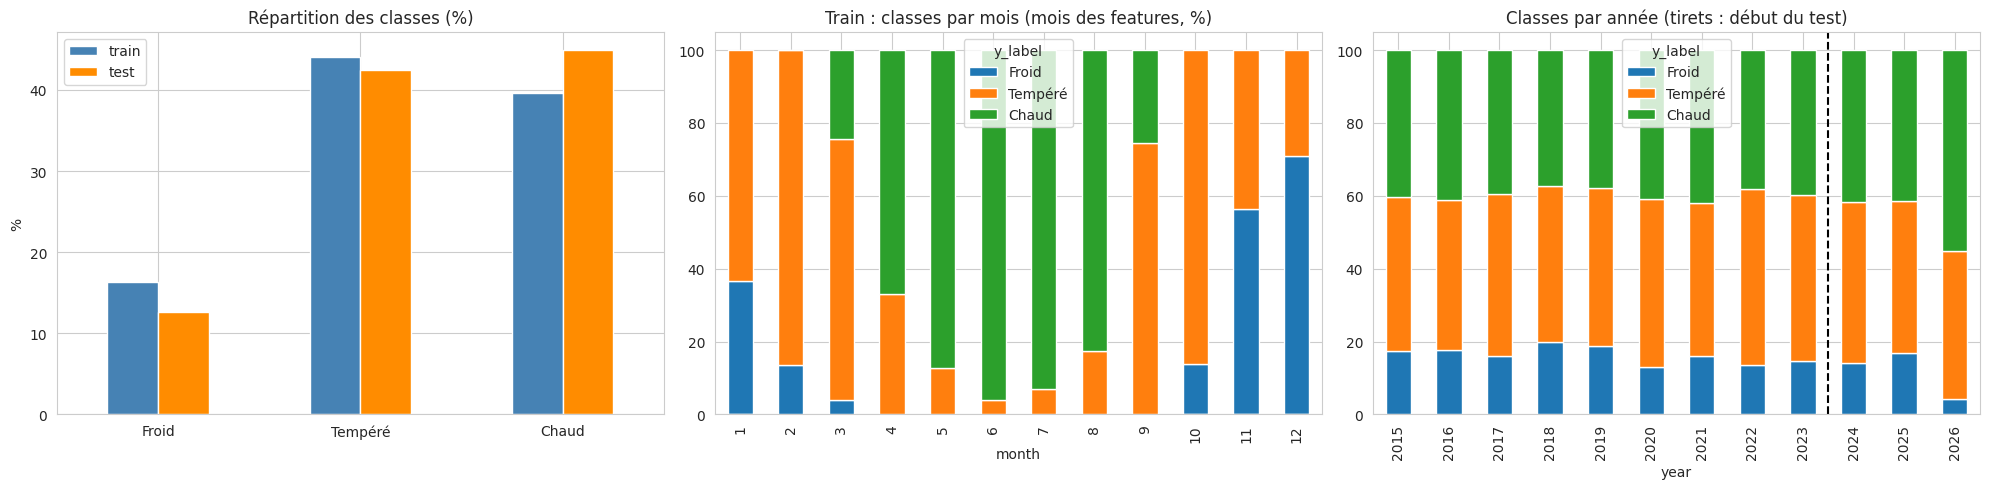

Mois couverts par année :


year,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
mois,12,12,12,12,12,12,12,12,12,12,12,8


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

dist.plot.bar(ax=axes[0], color=["steelblue", "darkorange"])
axes[0].set_title("Répartition des classes (%)"); axes[0].set_ylabel("%"); axes[0].tick_params(axis="x", rotation=0)

pd.crosstab(train["month"], train["y_label"], normalize="index").mul(100).plot.bar(stacked=True, ax=axes[1])
axes[1].set_title("Train : classes par mois (mois des features, %)")

full = pd.concat([train.assign(jeu="train"), test.assign(jeu="test")])
par_an = pd.crosstab(full["year"], full["y_label"], normalize="index").mul(100)
par_an.plot.bar(stacked=True, ax=axes[2])
axes[2].axvline(train["year"].nunique() - 0.5, color="k", ls="--")
axes[2].set_title("Classes par année (tirets : début du test)")
plt.tight_layout(); plt.show()

print("Mois couverts par année :"); display(full.groupby("year")["month"].nunique().to_frame("mois").T)

**Note : analyse des classes**

**Ce que nous avons fait.** Nous avons calculé les pourcentages de chaque classe dans le train et dans le test, leur répartition par mois et par année, et le rapport de déséquilibre (classe la plus fréquente sur la moins fréquente).

**Justification.**
- Des intervalles de largeur égale ne donnent pas des classes de même effectif : le déséquilibre doit être mesuré avant de choisir les métriques.
- La température est fortement saisonnière : la classe dépend largement du mois. C'est ce qui rend les baselines saisonnières difficiles à battre.
- La distribution diffère entre train et test, car le test contient 2026, année incomplète (mois manquants). L'accuracy seule serait donc trompeuse : nous utiliserons l'accuracy et le F1-macro.

### Baselines de référence (hors échantillon)

Tout est appris sur le train et évalué sur le test. Ces scores sont la barre à dépasser à l'étape 2. La baseline « cellule × mois » utilise l'identifiant de cellule, que les features du modèle n'incluent pas : c'est donc un repère très favorable.

In [ ]:
def evaluer(nom, y_pred):
    return {"modèle": nom, "accuracy": accuracy_score(test["y"], y_pred),
            "F1-macro": f1_score(test["y"], y_pred, average="macro")}

res = []

# 1) classe majoritaire du train
res.append(evaluer("Classe majoritaire", np.full(len(test), train["y"].mode()[0])))

# 2) classe majoritaire par mois (mois courant), apprise sur le train
maj_mois = train.groupby("month")["y"].agg(lambda s: s.mode()[0])
res.append(evaluer("Mois seul (majoritaire)", test["month"].map(maj_mois).values))

# 3) persistance : classe de t2m(t) utilisée comme prédiction de la classe de t2m(t+1)
res.append(evaluer("Persistance", to_class(test["t2m"])))

# 4) climatologie cellule x mois : t2m(t+1) moyenne du train pour (cellule, mois courant)
clim = train.groupby(["cell_id", "month"])["t2m_next"].mean().rename("clim").reset_index()
tmp = test[["cell_id", "month"]].merge(clim, on=["cell_id", "month"], how="left")
assert tmp["clim"].notna().all()
res.append(evaluer("Climatologie cellule x mois", to_class(tmp["clim"].values)))

baselines = pd.DataFrame(res).set_index("modèle").round(4)
baselines

,accuracy,F1-macro
modèle,,
Classe majoritaire,0.4246,0.1987
Mois seul (majoritaire),0.8067,0.7687
Persistance,0.7393,0.7108
Climatologie cellule x mois,0.9370,0.9247


**Note : baselines de référence**

**Ce que nous avons fait.** Nous avons calculé quatre baselines, apprises sur le train et évaluées sur le test (accuracy et F1-macro) : classe majoritaire, majoritaire par mois, persistance (classe de la `t2m` courante) et climatologie cellule × mois.

**Justification.**
- Elles donnent la barre à dépasser : la saisonnalité seule explique une grande partie de la cible, et un modèle n'a de valeur que s'il fait mieux que ces références.
- La climatologie cellule × mois utilise `cell_id`, que les features du modèle n'incluent pas : c'est un repère particulièrement favorable.
- La persistance utilise `t2m_current`, qui n'est pas une feature du modèle (énoncé) : elle sert uniquement de comparaison.

## 9. Contrôles finaux et sauvegarde

In [ ]:
META = ["cell_id", "latitude", "longitude", "time", "time_next", "t2m_current"]
TARGETS = ["t2m_next", "y", "y_label"]

def assemble(X, d):
    out = pd.concat([d[["cell_id", "latitude", "longitude", "time", "time_next"]].reset_index(drop=True),
                     d[["t2m"]].rename(columns={"t2m": "t2m_current"}).reset_index(drop=True),
                     X.reset_index(drop=True),
                     d[TARGETS].reset_index(drop=True)], axis=1)
    return out

train_final = assemble(Xtr, train)
test_final  = assemble(Xte, test)

# --- contrôles ---
for nom, d in [("train", train_final), ("test", test_final)]:
    assert d[FEATURES].notna().all().all(), f"NaN dans {nom}"
    assert np.isfinite(d[FEATURES].to_numpy()).all(), f"Inf dans {nom}"
    assert set(d["y"].unique()) <= {0, 1, 2}
assert list(train_final[FEATURES].columns) == list(test_final[FEATURES].columns)
assert train_final["time"].max() < test_final["time"].min()
print("Contrôles OK")
print("train :", train_final.shape, "| test :", test_final.shape)

# --- sauvegarde ---
train_final.to_parquet(f"{OUT_DIR}/supervised_train.parquet", index=False)
test_final.to_parquet(f"{OUT_DIR}/supervised_test.parquet", index=False)
joblib.dump(scaler, f"{OUT_DIR}/robust_scaler.joblib")

config = {
    "input_file": IN_FILE,
    "test_start": str(TEST_START.date()),
    "dropped_correlated_vars": DROP_CORR,
    "corr_threshold": CORR_THRESHOLD,
    "corr_criterion": "max(|pearson|, |spearman|) on all rows, features only (no target); keep the variable ranked first in KEEP_PRIORITY",
    "keep_priority": KEEP_PRIORITY,
    "corr_pairs_removed": table_corr.to_dict(orient="records") if len(table_corr) else [],
    "neg_log_vars": [v for v in NEG_LOG_VARS if v in FEATURES_CLIM],
    "pos_log1p_vars": [v for v in POS_LOG1P_VARS if v in FEATURES_CLIM],
    "pos_log1p_scale_s": pos_scale,
    "class_names": CLASS_NAMES,
    "class_edges_celsius": [float(e) for e in edges],
    "features": FEATURES,
    "scaled_features": SCALE_COLS,
    "unscaled_features": CYCLIC_COLS,
    "meta_columns_not_for_training": META,
    "target_columns": TARGETS,
    "class_percent_train": {k: float(v) for k, v in zip(CLASS_NAMES, dist["train"])},
    "class_percent_test": {k: float(v) for k, v in zip(CLASS_NAMES, dist["test"])},
}
with open(f"{OUT_DIR}/preprocessing_config.json", "w", encoding="utf-8") as f:
    json.dump(config, f, ensure_ascii=False, indent=2)

print("Fichiers écrits dans :", OUT_DIR)
print(sorted(os.listdir(OUT_DIR)))

Contrôles OK
train : (585900, 23) | test : (173600, 23)
Fichiers écrits dans : /content/drive/MyDrive/data mining/supervised_dataset
['preprocessing_config.json', 'robust_scaler.joblib', 'supervised_test.parquet', 'supervised_train.parquet']


In [ ]:
# Relecture : le dataset sauvegardé est bien prêt à l'emploi
tr = pd.read_parquet(f"{OUT_DIR}/supervised_train.parquet")
te = pd.read_parquet(f"{OUT_DIR}/supervised_test.parquet")
cfg = json.load(open(f"{OUT_DIR}/preprocessing_config.json", encoding="utf-8"))

X_tr, y_tr = tr[cfg["features"]], tr["y"]
X_te, y_te = te[cfg["features"]], te["y"]
print(X_tr.shape, X_te.shape, "| classes train :", y_tr.value_counts(normalize=True).sort_index().round(3).to_dict())
tr.head()

(585900, 14) (173600, 14) | classes train : {0: 0.163, 1: 0.44, 2: 0.396}


,cell_id,latitude,longitude,time,time_next,t2m_current,d2m,slhf,ssr,str,sshf,ro,u10,v10,sp,tp,month,year,month_sin,month_cos,t2m_next,y,y_label
0,0,18.95,3.35,2015-01-01,2015-02-01,16.053375,-1.378827,-1.021888,-0.570481,0.221395,0.652215,-0.308532,-1.145371,-1.437461,0.098373,-0.373475,-1.000000,-1.0,0.500000,8.660254e-01,21.763580,1,Tempéré
1,0,18.95,3.35,2015-02-01,2015-03-01,21.763580,-1.198452,-0.004375,-0.307223,0.008139,0.451204,0.613105,-0.204426,-0.881990,-0.015626,0.487498,-0.818182,-1.0,0.866025,5.000000e-01,24.019196,1,Tempéré
2,0,18.95,3.35,2015-03-01,2015-04-01,24.019196,-0.740159,-0.379721,-0.133635,0.014514,0.085011,0.364216,-0.543537,-1.170387,-0.026693,0.270026,-0.636364,-1.0,1.000000,6.123234e-17,27.534332,2,Chaud
3,0,18.95,3.35,2015-04-01,2015-05-01,27.534332,-1.923437,-0.231058,0.398471,-0.841304,-0.073169,-0.308532,-1.134510,-0.606417,-0.009623,-0.374808,-0.454545,-1.0,0.866025,-5.000000e-01,33.414703,2,Chaud
4,0,18.95,3.35,2015-05-01,2015-06-01,33.414703,-0.777201,0.051735,0.420268,-0.861591,-0.048609,-0.308532,-0.449265,0.056913,-0.089108,-0.384027,-0.272727,-1.0,0.500000,-8.660254e-01,35.476715,2,Chaud


**Note : contrôles finaux et sauvegarde**

**Ce que nous avons fait.** Nous avons vérifié l'absence de NaN et d'infinis, l'identité des colonnes entre train et test et la séparation temporelle, puis sauvegardé le train et le test (parquet), le scaler (joblib) et la configuration (JSON : variables supprimées, `s`, bornes des classes, liste des features).

**Justification.**
- **Reproductibilité** : l'étape 2 recharge exactement le même dataset, et le scaler et les paramètres sauvegardés permettent d'appliquer les mêmes transformations à de nouvelles données.
- Les colonnes de métadonnées (`cell_id`, `time`, `t2m_current`, `t2m_next`...) sont séparées de la liste des features, pour éviter qu'une colonne contenant de l'information sur la cible serve par erreur à l'entraînement.

## Utilisation à l'étape 2

```python
tr = pd.read_parquet(f"{OUT_DIR}/supervised_train.parquet")
te = pd.read_parquet(f"{OUT_DIR}/supervised_test.parquet")
cfg = json.load(open(f"{OUT_DIR}/preprocessing_config.json", encoding="utf-8"))
X_tr, y_tr = tr[cfg["features"]], tr["y"]
X_te, y_te = te[cfg["features"]], te["y"]
```

- Les colonnes `META` (dont `t2m_current`, `time`, `cell_id`) et `t2m_next` ne doivent **pas** servir de features.
- Pour régler les hyperparamètres, utiliser une validation chronologique **dans le train** (par exemple `TimeSeriesSplit` sur les mois), jamais une validation croisée mélangée.